# 03. Improving the plain PINN

Notebook 02 left two loose ends. On the smooth problem (S) the plain PINN came close to the target. On the step problem (A), where the field jumps from 0 to 1 at the boundary at τ = 0, it did not: the error concentrates in the early-time corner near ξ = 0.

This notebook tries four standard fixes, one at a time, and measures each against the plain PINN under the same network, optimizer budget and precision.

- **Hard constraints**: build the boundary (and, for R, initial) conditions into the network output, so they hold exactly and are not part of the loss.
- **Loss weighting**: manual weights, and gradient-based adaptive weights.
- **Residual-adaptive sampling (RAD)**: move collocation points toward where the PDE residual is large.
- **Causal training**: weight the residual at later times by how well earlier times are already fit.

It also adds a **new problem, R**: the applied field ramps up smoothly, b(0, τ) = g(τ), over τ_r = 0.05 instead of jumping. This removes the discontinuity at the corner, which is a more realistic boundary condition for a driven coil. R has its own reference solution (Duhamel's principle applied to the step solution), cross-checked with a finite-difference solver below.

**What to take from this notebook:** the numbers are for one network size, one budget, and 3 to 6 seeds. They say which ideas helped *here*, not which are generally better. Where a setting was not tuned, the text says so.

In [1]:
import os, pickle, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Variant R: a smooth ramp in time at the boundary

The applied field rises as $g(\tau)$, a quintic smoothstep from 0 to 1 over $\tau_r = 0.05$, and then stays at 1 (initial condition 0, right boundary 0). The exact solution follows from the step solution by Duhamel's principle: $b_R(\xi,\tau)=\int_0^{\min(\tau,\tau_r)} g'(s)\, b_A(\xi,\tau-s)\,ds$, with $b_A$ the method-of-images form from notebook 01 evaluated by Gauss-Legendre quadrature. As in notebook 01, the finite-difference solver (here with a time-dependent boundary value) is an independent check, and the analytic form is the arbiter.

In [2]:
import numpy as np
from scipy.special import erfc
from scipy.linalg import solve_banded

TAU_R = 0.05

def g(t, tau_r=TAU_R):
    x = np.clip(t / tau_r, 0.0, 1.0)
    return x**3 * (10 - 15 * x + 6 * x**2)

def gprime(t, tau_r=TAU_R):
    x = np.clip(t / tau_r, 0.0, 1.0)
    return 30 * x**2 * (1 - x)**2 / tau_r * ((t > 0) & (t < tau_r))

def bA(xi, u, kmax=30):
    """Exact step solution (method of images); u > 0, broadcasting."""
    xi = np.asarray(xi, float); u = np.asarray(u, float)
    s = 2 * np.sqrt(u)
    out = np.zeros(np.broadcast(xi, u).shape)
    for k in range(kmax):
        out = out + erfc((2 * k + xi) / s) - erfc((2 * k + 2 - xi) / s)
    return out

def ref_R(xi_grid, tau_grid, tau_r=TAU_R, n_gl=200):
    x, w = np.polynomial.legendre.leggauss(n_gl)
    out = np.zeros((len(tau_grid), len(xi_grid)))
    for i, tau in enumerate(tau_grid):
        T = min(tau, tau_r)
        s = 0.5 * T * (x + 1); ws = 0.5 * T * w
        gp = gprime(s, tau_r)
        u = np.maximum(tau - s, 1e-300)
        vals = bA(xi_grid[None, :], u[:, None])
        out[i] = (ws * gp) @ vals
    return out

def fd_R(N, nsteps, tau_end, tau_r=TAU_R):
    """Crank-Nicolson FD with time-dependent left boundary g(tau)."""
    h = 1.0 / N; dt = tau_end / nsteps; r = dt / h**2
    n = N - 1
    ab = np.zeros((3, n)); ab[0, 1:] = -r / 2; ab[1] = 1 + r; ab[2, :-1] = -r / 2
    b = np.zeros(N + 1); hist = [b.copy()]
    for k in range(nsteps):
        t0, t1 = k * dt, (k + 1) * dt
        rhs = (1 - r) * b[1:N] + r / 2 * (b[0:N - 1] + b[2:N + 1])
        rhs[0] += r / 2 * g(t1, tau_r)   # new-time left boundary
        b[0] = g(t1, tau_r)
        b[1:N] = solve_banded((1, 1), ab, rhs)
        hist.append(b.copy())
    return np.array(hist)

In [3]:
ref = np.load("../data/reference_fields.npz")
xi_g, tau_g = ref["xi"], ref["tau"]
REF = {"A": ref["ref_A"]}
REF["R"] = ref_R(xi_g, tau_g, n_gl=600)

# checks: boundary values, quadrature convergence, finite-difference agreement
print("left boundary error:", np.abs(REF["R"][:, 0] - g(tau_g)).max(), " right boundary:", np.abs(REF["R"][:, -1]).max())
print("Gauss-Legendre 600 vs 1200 nodes, max difference:", np.abs(REF["R"] - ref_R(xi_g, tau_g, n_gl=1200)).max())
for N, ns in [(400, 4000), (800, 8000)]:
    H = fd_R(N, ns, 0.5)
    idx = np.round(tau_g / 0.5 * ns).astype(int)
    xs = np.linspace(0, 1, N + 1)
    FD = np.array([np.interp(xi_g, xs, H[i]) for i in idx])
    e = FD - REF["R"]
    print(f"FD N={N}: max |FD - reference| = {np.abs(e).max():.2e}, relative L2 = {np.linalg.norm(e)/np.linalg.norm(REF['R']):.2e}")

left boundary error: 1.9539925233402755e-14  right boundary: 0.0


Gauss-Legendre 600 vs 1200 nodes, max difference: 5.253153467776883e-10
FD N=400: max |FD - reference| = 4.64e-06, relative L2 = 1.31e-06


FD N=800: max |FD - reference| = 1.16e-06, relative L2 = 3.26e-07


## 2. The PINN variants

Same network, optimizer budget (2000 Adam steps, then 2000 L-BFGS iterations), seeds (0, 1, 2; extended to six for the main comparisons) and float32 precision as notebook 02, so the plain-PINN numbers there are the baseline for problem A. Each change is applied alone:

- **hard**: the boundary condition (problem A) or both boundary and initial conditions (problem R) are satisfied exactly by an output transformation. For A the initial condition stays a soft loss term, because the step is incompatible with any smooth ansatz that satisfies both.
- **w_manual**: boundary and initial terms weighted 10 times the PDE term. This value was chosen as a common rule of thumb, not tuned.
- **w_adapt**: weights adjusted every 50 Adam steps from the ratio of gradient magnitudes (learning-rate annealing, Wang et al. 2021).
- **rad**: residual-adaptive sampling; every 100 Adam steps a pool of 20,000 candidate points is scored by $|r|$ and collocation points are drawn with probability proportional to $|r|/\overline{|r|}+1$.
- **causal**: residual weights over 16 time bins (denser at early time) decay with the accumulated residual of earlier bins, $\exp(-\epsilon \sum_{j<i} L_j)$, with $\epsilon = 10$ (not tuned).

In [4]:
import time
import numpy as np
import torch
import torch.nn as nn

TAU_MAX = 0.5
TAU_R = 0.05
EARLY = 0.05          # "early-time window" tau <= EARLY used for diagnostics
CAUSAL_BINS = 16


def g_t(t):
    x = torch.clamp(t / TAU_R, 0.0, 1.0)
    return x ** 3 * (10 - 15 * x + 6 * x ** 2)


PROBLEMS = {
    "A": dict(bc_left=lambda tau: torch.ones_like(tau)),
    "R": dict(bc_left=g_t),
}


class MLP(nn.Module):
    def __init__(self, width=64, depth=4):
        super().__init__()
        layers, d_in = [], 2
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.Tanh()]
            d_in = width
        layers += [nn.Linear(d_in, 1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, xi, tau):
        return self.net(torch.cat([xi, tau], dim=1))


def field(model, xi, tau, prob, hard):
    """b(xi, tau). With hard=True the boundary (and, for R, initial) conditions hold by construction."""
    n = model(xi, tau)
    if not hard:
        return n
    if prob == "A":      # b(0)=1, b(1)=0 exactly; initial condition stays a soft loss term
        return (1 - xi) + xi * (1 - xi) * n
    # R: b(0)=g(tau), b(1)=0, and b(xi,0)=0 exactly
    return g_t(tau) * (1 - xi) + xi * (1 - xi) * tau * n


def pde_residual(model, xi, tau, prob, hard):
    xi = xi.clone().requires_grad_(True)
    tau = tau.clone().requires_grad_(True)
    b = field(model, xi, tau, prob, hard)
    ones = torch.ones_like(b)
    b_tau = torch.autograd.grad(b, tau, ones, create_graph=True)[0]
    b_xi = torch.autograd.grad(b, xi, ones, create_graph=True)[0]
    b_xixi = torch.autograd.grad(b_xi, xi, torch.ones_like(b_xi), create_graph=True)[0]
    return b_tau - b_xixi


def causal_pde_loss(r, tau, eps, dtype):
    """Causal weighting of the residual over time bins (denser at early time)."""
    edges = TAU_MAX * (torch.arange(CAUSAL_BINS + 1, dtype=dtype) / CAUSAL_BINS) ** 2
    idx = torch.clamp(torch.bucketize(tau.squeeze(1).detach(), edges[1:-1]), 0, CAUSAL_BINS - 1)
    sums = torch.zeros(CAUSAL_BINS, dtype=dtype).index_add(0, idx, (r ** 2).squeeze(1))
    cnt = torch.zeros(CAUSAL_BINS, dtype=dtype).index_add(0, idx, torch.ones(idx.shape[0], dtype=dtype))
    L = sums / cnt.clamp(min=1)
    w = torch.exp(-eps * (torch.cumsum(L, 0) - L)).detach()
    return (w * L).mean()


def loss_terms(model, prob, cfg, pts, dtype):
    hard = cfg["hard"]
    r = pde_residual(model, pts["xi_f"], pts["tau_f"], prob, hard)
    pde_plain = (r ** 2).mean()
    l_pde = causal_pde_loss(r, pts["tau_f"], cfg["causal"], dtype) if cfg["causal"] > 0 else pde_plain
    zeros = torch.zeros_like(pts["tau_b"]); ones = torch.ones_like(pts["tau_b"])
    l_bc = ((field(model, zeros, pts["tau_b"], prob, hard) - PROBLEMS[prob]["bc_left"](pts["tau_b"])) ** 2).mean() \
         + ((field(model, ones, pts["tau_b"], prob, hard)) ** 2).mean()
    l_ic = (field(model, pts["xi_i"], torch.zeros_like(pts["xi_i"]), prob, hard) ** 2).mean()
    return l_pde, l_bc, l_ic, pde_plain.detach()


def uniform_points(n, dtype, gen):
    return torch.rand(n, 1, generator=gen, dtype=dtype), TAU_MAX * torch.rand(n, 1, generator=gen, dtype=dtype)


class Sampler:
    """Uniform collocation points, or residual-adaptive (RAD: p ~ |r|^k / mean + c)."""

    def __init__(self, mode, dtype, gen, n_pool=20000, k=1.0, c=1.0):
        self.mode, self.dtype, self.gen, self.n_pool, self.k, self.c = mode, dtype, gen, n_pool, k, c
        self.pool = None

    def refresh(self, model, prob, hard):
        if self.mode != "rad":
            return
        xi, tau = uniform_points(self.n_pool, self.dtype, self.gen)
        with torch.enable_grad():
            r = pde_residual(model, xi, tau, prob, hard).detach().abs().squeeze(1)
        p = r ** self.k
        p = p / p.mean() + self.c
        self.pool = (xi, tau, (p / p.sum()))

    def interior(self, n):
        if self.mode != "rad" or self.pool is None:
            return uniform_points(n, self.dtype, self.gen)
        xi, tau, p = self.pool
        idx = torch.multinomial(p, n, replacement=True, generator=self.gen)
        return xi[idx], tau[idx]

    def points(self, n_f, n_b, n_i):
        xi_f, tau_f = self.interior(n_f)
        return dict(xi_f=xi_f, tau_f=tau_f,
                    tau_b=TAU_MAX * torch.rand(n_b, 1, generator=self.gen, dtype=self.dtype),
                    xi_i=torch.rand(n_i, 1, generator=self.gen, dtype=self.dtype))


@torch.no_grad()
def predict(model, prob, hard, xi_grid, tau_grid, dtype):
    XI, TAU = np.meshgrid(xi_grid, tau_grid)
    x = torch.tensor(XI.reshape(-1, 1), dtype=dtype); t = torch.tensor(TAU.reshape(-1, 1), dtype=dtype)
    return field(model, x, t, prob, hard).numpy().reshape(XI.shape).astype(np.float64)


def residual_mse(model, prob, hard, dtype, n=20000, seed=12345):
    gen = torch.Generator().manual_seed(seed)
    xi, tau = uniform_points(n, dtype, gen)
    r = pde_residual(model, xi, tau, prob, hard)
    return float((r.detach().double() ** 2).mean())


def summarize(pred, ref, xi_grid, tau_grid):
    err = pred - ref
    k = np.unravel_index(np.argmax(np.abs(err)), err.shape)
    early = tau_grid <= EARLY
    return dict(rel_l2=float(np.linalg.norm(err) / np.linalg.norm(ref)),
                early_l2=float(np.linalg.norm(err[early]) / np.linalg.norm(ref[early])),
                max_abs=float(np.abs(err).max()),
                max_at=(float(xi_grid[k[1]]), float(tau_grid[k[0]])),
                bc_err=float(np.abs(err[:, 0]).max()))

In [5]:
def train(prob, cfg, ref, xi_grid, tau_grid, seed=0, dtype=torch.float32,
          n_adam=2000, n_lbfgs=2000, lr=1e-3, n_f=2048, n_b=256, n_i=256,
          n_f_lbfgs=8192, log_every=100, rad_every=100, adapt_every=50, verbose=False):
    cfg = dict(dict(hard=False, weights="equal", sampling="uniform", causal=0.0, lam_max=float("inf")), **cfg)
    hard = cfg["hard"]
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = MLP().to(dtype)
    params = list(model.parameters())
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / max(n_adam, 1)))
    smp = Sampler(cfg["sampling"], dtype, gen)
    lam = {"manual": [1.0, 10.0, 10.0]}.get(cfg["weights"], [1.0, 1.0, 1.0])
    hist = dict(step=[], pde=[], bc=[], ic=[], rel_l2=[], early_l2=[], lam_bc=[], lam_ic=[], phase=[])
    t0 = time.perf_counter()

    def log(step, terms, phase):
        pred = predict(model, prob, hard, xi_grid, tau_grid, dtype)
        s = summarize(pred, ref, xi_grid, tau_grid)
        hist["step"].append(step); hist["pde"].append(float(terms[3]))
        hist["bc"].append(float(terms[1])); hist["ic"].append(float(terms[2]))
        hist["rel_l2"].append(s["rel_l2"]); hist["early_l2"].append(s["early_l2"])
        hist["lam_bc"].append(lam[1]); hist["lam_ic"].append(lam[2]); hist["phase"].append(phase)

    def gnorm(term):
        if not term.requires_grad:
            return None
        gs = torch.autograd.grad(term, params, retain_graph=True, allow_unused=True)
        gs = [g.abs().flatten() for g in gs if g is not None]
        return torch.cat(gs) if gs else None

    for step in range(n_adam):
        if step % rad_every == 0:
            smp.refresh(model, prob, hard)
        pts = smp.points(n_f, n_b, n_i)
        terms = loss_terms(model, prob, cfg, pts, dtype)
        if cfg["weights"] == "adaptive" and step % adapt_every == 0 and step > 0:
            gp = gnorm(terms[0])
            for j in (1, 2):
                gj = gnorm(terms[j])
                if gp is not None and gj is not None and gj.mean() > 0:
                    lam[j] = min(cfg["lam_max"], 0.9 * lam[j] + 0.1 * float(gp.max() / gj.mean()))
        loss = lam[0] * terms[0] + lam[1] * terms[1] + lam[2] * terms[2]
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % log_every == 0:
            log(step, [t.detach() for t in terms], "adam")
            if verbose:
                print(step, [float(t) for t in terms], hist["rel_l2"][-1], flush=True)

    smp.refresh(model, prob, hard)
    fixed = smp.points(n_f_lbfgs, n_b * 4, n_i * 4)
    lb = torch.optim.LBFGS(params, lr=1.0, max_iter=25, history_size=50, tolerance_grad=1e-14,
                           tolerance_change=1e-16, line_search_fn="strong_wolfe")
    last = {}

    def closure():
        lb.zero_grad()
        terms = loss_terms(model, prob, cfg, fixed, dtype)
        loss = lam[0] * terms[0] + lam[1] * terms[1] + lam[2] * terms[2]
        loss.backward()
        last["terms"] = [t.detach() for t in terms]
        return loss

    for k in range(n_lbfgs // 25):
        lb.step(closure)
        log(n_adam + 25 * (k + 1), last["terms"], "lbfgs")
        if verbose and k % 8 == 0:
            print(n_adam + 25 * (k + 1), [float(t) for t in last["terms"]], hist["rel_l2"][-1], flush=True)

    wall = time.perf_counter() - t0
    pred = predict(model, prob, hard, xi_grid, tau_grid, dtype)
    m = summarize(pred, ref, xi_grid, tau_grid)
    m["res_mse"] = residual_mse(model, prob, hard, dtype)
    m["wall_s"] = wall; m["steps"] = n_adam + n_lbfgs
    m["lam"] = list(lam)
    return model, hist, m, pred

## 3. Results

Everything is loaded from the cached runs in `../results/` (re-running takes about 4 minutes per run on one CPU core). The plain-PINN baseline for A, seeds 0 to 2, is the notebook-02 run; all other runs use the code above. The two use the same network, budget and precision.

Metrics are the same as in notebook 02: relative L2 error on a 200 × 201 grid over τ ∈ (0, 0.5], the same error restricted to the early window τ ≤ 0.05, the largest pointwise error, the error at the ξ = 0 boundary, and the PDE residual on held-out random points. Each table entry is the median over seeds, with [min, max] beside it.

`w_adapt` is the uncapped adaptive weighting. It diverged, so `w_adapt_cap` (weights limited to 100) is shown next to it. `hard_w` is hard constraints plus manual weights, run only on A.

In [6]:
M2 = pickle.load(open("../results/m2_runs.pkl", "rb"))
RUNS = {}
for (p, dt, s), r in M2.items():
    if p == "A" and dt == "float32":
        m = summarize(r["pred"].astype(float), REF["A"], xi_g, tau_g)
        m["res_mse"] = r["metrics"]["res_mse"]; m["wall_s"] = r["metrics"]["wall_s"]
        RUNS[("A", "plain", s)] = dict(metrics=m, pred=r["pred"], hist=None)
for fn in ("m3_A", "m3_R", "m3b_1", "m3b_2", "m3b_3", "m3b_4", "m3b_5", "m3b_6", "m3b_7"):
    RUNS.update(pickle.load(open(f"../results/{fn}.pkl", "rb")))
CONFIGS = ["plain", "hard", "w_manual", "w_adapt", "w_adapt_cap", "rad", "causal", "hard_w"]
SEEDS3 = (0, 1, 2)
print(len(RUNS), "runs loaded")

def vals(prob, cfg, key, seeds=SEEDS3):
    return [RUNS[(prob, cfg, s)]["metrics"][key] for s in seeds if (prob, cfg, s) in RUNS]

def fmt(prob, cfg, key, seeds=SEEDS3):
    v = vals(prob, cfg, key, seeds)
    return f"{np.median(v):.2e} [{min(v):.1e},{max(v):.1e}]"

print("Ablations: one change at a time, seeds 0, 1, 2 (median [min, max])")
for prob in ("A", "R"):
    print(f"\nProblem {prob}")
    print(f"{'config':12s} {'rel L2':>24s} {'early (tau<=0.05) L2':>24s} {'max |err|':>10s} {'bc err':>8s} {'PDE res MSE':>12s}")
    for cfg in CONFIGS:
        if not vals(prob, cfg, "rel_l2"): continue
        print(f"{cfg:12s} {fmt(prob,cfg,'rel_l2'):>24s} {fmt(prob,cfg,'early_l2'):>24s} {np.median(vals(prob,cfg,'max_abs')):10.2e} {np.median(vals(prob,cfg,'bc_err')):8.1e} {np.median(vals(prob,cfg,'res_mse')):12.2e}")

66 runs loaded
Ablations: one change at a time, seeds 0, 1, 2 (median [min, max])

Problem A
config                         rel L2     early (tau<=0.05) L2  max |err|   bc err  PDE res MSE
plain        1.33e-02 [7.5e-03,1.4e-02] 5.85e-02 [3.1e-02,6.4e-02]   2.66e-01  2.4e-01     8.22e-04
hard         2.06e-03 [1.5e-03,1.1e-02] 1.03e-02 [7.6e-03,5.6e-02]   2.87e-02  2.2e-16     1.82e+00
w_manual     3.89e-03 [3.9e-03,5.1e-03] 1.40e-02 [1.0e-02,2.1e-02]   4.52e-02  3.3e-02     1.49e-01
w_adapt      2.34e-01 [1.8e-01,2.4e-01] 7.62e-02 [5.2e-02,1.5e-01]   2.28e-01  1.5e-02     2.05e+01
w_adapt_cap  5.14e-03 [5.0e-03,8.3e-03] 2.25e-02 [2.2e-02,3.9e-02]   7.76e-02  1.8e-02     4.50e-01
rad          1.54e-02 [1.3e-02,1.6e-02] 6.53e-02 [5.5e-02,7.5e-02]   2.91e-01  2.8e-01     4.47e-04
causal       1.71e-02 [1.6e-02,4.0e-02] 8.30e-02 [7.2e-02,1.9e-01]   3.78e-01  3.8e-01     5.07e-04
hard_w       7.45e-03 [5.6e-03,7.6e-03] 3.30e-02 [2.7e-02,3.7e-02]   1.13e-01  2.2e-16     2.81e+01

Problem R


In [7]:
# Six seeds (0-5) for the configurations that matter most
SEEDS6 = (0, 1, 2, 3, 4, 5)
print("Six seeds (0-5), relative L2 error")
SIX = {"A": ("plain", "hard", "w_manual", "w_adapt_cap"), "R": ("plain", "hard")}
for prob in ("A", "R"):
    for cfg in SIX[prob]:
        v = vals(prob, cfg, "rel_l2", SEEDS6)
        print(f"{prob} {cfg:6s} n={len(v)}  rel L2 per seed: " + " ".join(f"{x:.1e}" for x in v) + f"   median {np.median(v):.2e}")

Six seeds (0-5), relative L2 error
A plain  n=6  rel L2 per seed: 1.3e-02 7.5e-03 1.4e-02 1.4e-02 7.2e-03 1.4e-02   median 1.36e-02
A hard   n=6  rel L2 per seed: 2.1e-03 1.5e-03 1.1e-02 2.3e-03 4.7e-03 7.5e-03   median 3.54e-03
A w_manual n=6  rel L2 per seed: 3.9e-03 3.9e-03 5.1e-03 1.6e-03 3.1e-03 7.0e-03   median 3.88e-03
A w_adapt_cap n=6  rel L2 per seed: 5.1e-03 5.0e-03 8.3e-03 1.2e-03 4.1e-03 7.4e-03   median 5.07e-03
R plain  n=6  rel L2 per seed: 3.5e-03 4.3e-03 3.5e-03 6.2e-03 3.2e-03 3.7e-03   median 3.57e-03
R hard   n=6  rel L2 per seed: 2.5e-04 1.2e-04 9.7e-05 1.1e-04 9.9e-05 1.2e-04   median 1.14e-04


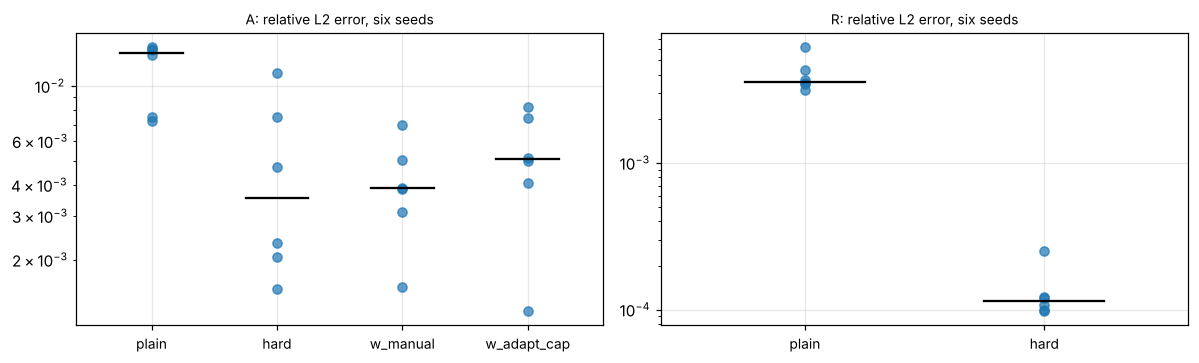

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, prob in zip(axes, ("A", "R")):
    for x, cfg in enumerate(SIX[prob]):
        v = vals(prob, cfg, "rel_l2", SEEDS6)
        ax.semilogy([x] * len(v), v, "o", color="C0", alpha=0.7)
        ax.semilogy([x - 0.25, x + 0.25], [np.median(v)] * 2, "k-", lw=1.5)
    ax.set_xticks(range(len(SIX[prob]))); ax.set_xticklabels(SIX[prob], fontsize=9)
    ax.set_xlim(-0.6, len(SIX[prob]) - 0.4); ax.set_title(f"{prob}: relative L2 error, six seeds", fontsize=9)
plt.tight_layout(); plt.show()

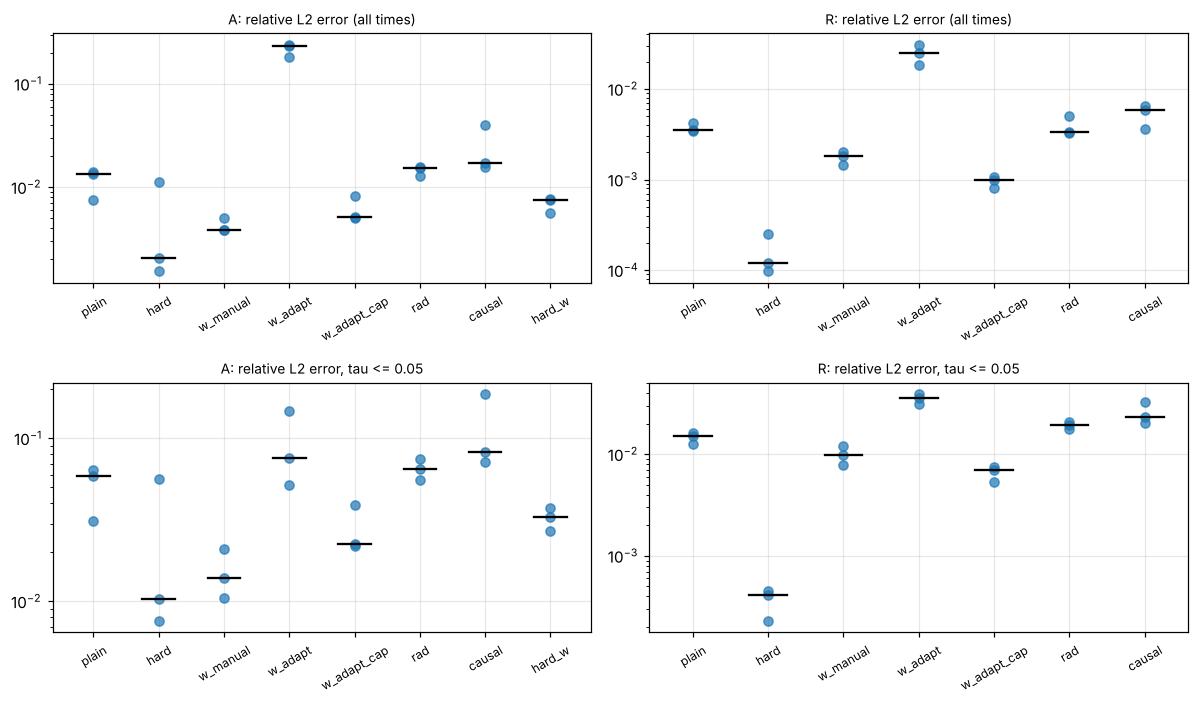

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for j, prob in enumerate(("A", "R")):
    for i, (key, title) in enumerate((("rel_l2", "relative L2 error (all times)"), ("early_l2", "relative L2 error, tau <= 0.05"))):
        ax = axes[i, j]
        present = [c for c in CONFIGS if (prob, c, 0) in RUNS]
        for x, cfg in enumerate(present):
            v = vals(prob, cfg, key)
            ax.semilogy([x] * len(v), v, "o", color="C0", alpha=0.7)
            ax.semilogy([x - 0.25, x + 0.25], [np.median(v)] * 2, "k-", lw=1.5)
        ax.set_xticks(range(len(present))); ax.set_xticklabels(present, rotation=30, fontsize=8)
        ax.set_title(f"{prob}: {title}", fontsize=9)
plt.tight_layout(); plt.show()

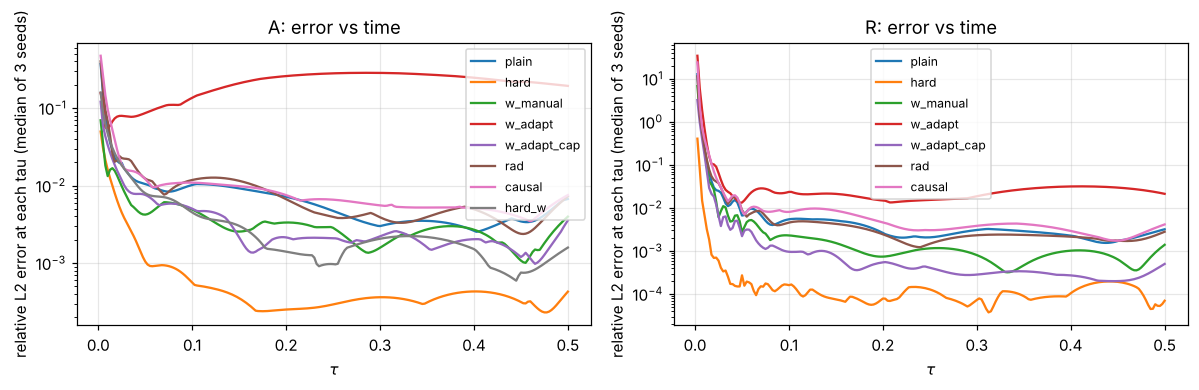

In [10]:
def err_vs_tau(prob, ax, cfgs):
    for cfg in cfgs:
        if (prob, cfg, 0) not in RUNS: continue
        e = np.array([RUNS[(prob, cfg, s)]["pred"].astype(float) - REF[prob] for s in (0, 1, 2)])
        rel = np.linalg.norm(e, axis=2) / np.linalg.norm(REF[prob], axis=1)
        ax.semilogy(tau_g, np.median(rel, axis=0), label=cfg)
    ax.set_xlabel(r"$\tau$"); ax.set_ylabel("relative L2 error at each tau (median of 3 seeds)"); ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
err_vs_tau("A", axes[0], CONFIGS); axes[0].set_title("A: error vs time")
err_vs_tau("R", axes[1], CONFIGS); axes[1].set_title("R: error vs time")
plt.tight_layout(); plt.show()

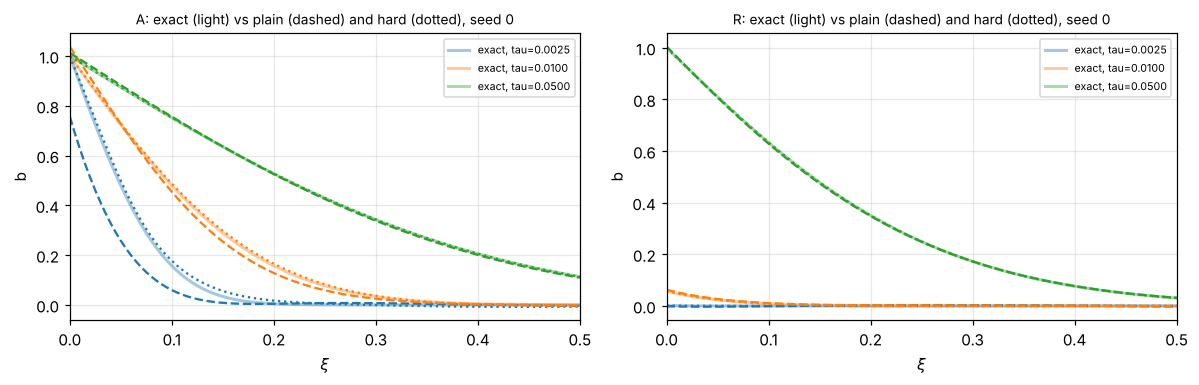

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, prob, cfgs in ((axes[0], "A", ["plain", "hard"]), (axes[1], "R", ["plain", "hard"])):
    for t, col in zip((0.0025, 0.01, 0.05), ("C0", "C1", "C2")):
        k = np.argmin(np.abs(tau_g - t))
        ax.plot(xi_g, REF[prob][k], color=col, lw=2, alpha=0.4, label=f"exact, tau={tau_g[k]:.4f}")
        for cfg, ls in zip(cfgs, ("--", ":")):
            ax.plot(xi_g, RUNS[(prob, cfg, 0)]["pred"][k], ls, color=col, lw=1.5)
    ax.set_xlim(0, 0.5); ax.set_xlabel(r"$\xi$"); ax.set_ylabel("b"); ax.legend(fontsize=7)
    ax.set_title(f"{prob}: exact (light) vs {cfgs[0]} (dashed) and {cfgs[1]} (dotted), seed 0", fontsize=9)
plt.tight_layout(); plt.show()

## 4. What the results say

**Problem R (smooth ramp).** Hard constraints help a great deal. Over six seeds the relative L2 error drops from a median of 3.6e-3 (plain) to 1.1e-4, about 31 times smaller, and every hard-constrained seed (9.7e-5 to 2.5e-4) beats every plain seed (3.2e-3 to 6.2e-3). Here the exact boundary and initial conditions leave the network only a smooth interior problem to solve, and it solves it well. Manual and capped adaptive weights give a smaller gain (about 2 to 4 times); RAD and causal training give none.

**Problem A (step).** Everything that helps gives a similar, modest gain, roughly 3 to 4 times over plain, and nothing gets below 1e-3.

| six seeds, rel. L2, median [min, max] | |
|---|---|
| plain | 1.4e-2 [7.2e-3, 1.4e-2] |
| hard | 3.5e-3 [1.5e-3, 1.1e-2] |
| manual weights (1, 10, 10) | 3.9e-3 [1.6e-3, 7.0e-3] |
| capped adaptive weights | 5.1e-3 [1.2e-3, 8.3e-3] |

The spread between seeds is as large as the differences between these three, so this data cannot say which is best. Hard constraints have the best single runs and also the worst (1.1e-2, barely better than plain). Manual weighting is more consistent but not clearly better. The hard-constrained network also has an enormous PDE residual (three-seed median MSE 1.8, versus 8e-4 for plain): it satisfies the boundary condition exactly and pays for it in the corner, where the true solution is nearly discontinuous and the residual is large. Adding manual weights to hard constraints (`hard_w`) was worse than hard alone.

**What did not help.** RAD and causal training, each with a single untuned setting, were no better than plain on either problem and slightly worse on some. Uncapped adaptive weighting diverged: the weights grew to 1e5 to 1e6 and the PDE residual stayed large. That is a real failure of this particular implementation (gradient-ratio rule, update every 50 steps), and capping at 100 was a fix I chose after seeing it.

**Reading the error-versus-time figure.** On A, the error is largest at the earliest times for every method and, for all but the uncapped adaptive run, falls by roughly one to two orders of magnitude by τ ≈ 0.2. On R the relative error at the first few τ values is huge for every method, but that is because the true field there is almost zero, so any absolute error looks large in relative terms. The absolute and L2 numbers are the better guide.

**Interpretation, with the caveat that it is an interpretation.** The step problem is hard because the solution has a boundary layer of width about √τ that shrinks to zero as τ → 0, and a smooth tanh network has to represent a feature that gets arbitrarily thin. Ramping the boundary value removes that feature, and the improvement from hard constraints on R (31 times) versus A (about 4 times) is consistent with that. I have not run an experiment that isolates this explanation.

## 5. Summary and caveats

**M3 status.** The M3 acceptance criterion asks for a stated, seed-reproducible error on A and the effect of each change quantified. On A, over six seeds, the best configurations reach a median relative L2 error of 3.5e-3 (hard constraints, range 1.5e-3 to 1.1e-2) and 3.9e-3 (manual weights, range 1.6e-3 to 7.0e-3), against 1.4e-2 for the plain PINN. That is about a 4-times improvement, and A is not solved to the 1e-3 level. Problem R, the smooth-ramp version, is solved to better than 3e-4 on every one of six seeds with hard constraints.

**What I would carry forward.** Use hard constraints, and use the ramped boundary (R) as the main test problem, with A as a stress test. Keep the plain PINN as the baseline.

**Things to keep in mind when reading these results:**

- Manual weights (1, 10, 10) and the causal strength ε = 10 were each tried once and not tuned. A sweep could change the picture for those two.
- The cap on the adaptive weights was chosen after seeing the uncapped run diverge.
- Hard constraints with manual weights (`hard_w`) was tested on seeds 0 to 5, and the choice to try it came from looking at seeds 0 to 2, so its result is slightly less independent than the others.
- Main comparisons use six seeds. The ablation table uses the first three; the extra seeds were added for the configurations that mattered most. Six seeds are enough to see a 30-times effect but not a 20 percent one.
- Plain-PINN A seeds 0 to 2 come from notebook 02's code (same network, budget and precision); seeds 3 to 5 come from this notebook's code.
- Wall-clock times are from a shared two-core machine with single-threaded jobs, not a clean benchmark.
- All M3 runs are float32. Float64 was not repeated here.

**Next:** M4, the inverse problem (recovering a resistivity or a boundary drive from sparse measurements), using the R setup with hard constraints.

## 6. Possible follow-up: sweep of the manual loss weights (not run)

The manual weights used above, (λ_pde, λ_bc, λ_ic) = (1, 10, 10), were tried once and not tuned. This is the plan for tuning them if it is worth coming back to. Only the ratios matter, so the PDE weight stays at 1 and the other two vary on a log scale.

**Step 1: one knob, λ_bc = λ_ic = λ.**
Values: 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000. The low end checks that 10 is not already too high. The high end is where trouble is expected: the capped adaptive run kept hitting its cap of 100, and the uncapped one ran away to 1e5 to 1e6 and failed. Expected on A: a shallow optimum somewhere between 10 and 300. Expected on R: a flatter response.

**Step 2: separate the two weights (only if step 1 shows a clear trend).**
A 3 × 3 grid of λ_bc and λ_ic over {1, 10, 100}. At the corner of A the initial condition says b = 0 and the boundary condition says b = 1, so the two terms may want different weights.

**Step 3: hard constraints plus weights.**
With hard constraints the boundary term is exact, so on A only the initial-condition weight matters. Values: λ_ic in {0.1, 0.3, 1, 3, 10}. The `hard_w` run used 10 and was worse than hard alone, so the better setting is likely at or below 1. On R both terms are exact, so there is nothing to sweep.

**Keeping the comparison honest.**
- Tune on fresh seeds (10 to 12), then rerun the winner on seeds 0 to 5, so the final numbers are not selected on the seeds they are reported on.
- Cost: step 1 on A is 9 values × 3 seeds, about 27 runs at roughly 4 minutes each, or about an hour on two cores. Doing R as well doubles that, and steps 2 and 3 add roughly another hour.
- Do A first. R is lower priority, because hard constraints there are already about 30 times better than any weighting scheme tried.
- Context for the payoff: on A, manual weighting (median 3.9e-3) is statistically indistinguishable from hard constraints (3.5e-3) across six seeds, so a sweep would be looking for a gain beyond that, not just a tie.